In [1]:
pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [64]:
#importing packages

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

In [168]:
#Loading all files and creating Target Column

normal= pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_Normal.csv",header=None)
normal["attack"]= "Normal"

back= pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back.csv",header=None)
back["attack"]= "back"

Buffer= pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_BufferOverflow.csv",header=None)
Buffer["attack"]= "BufferOverflow"

FTP = pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_FTPWrite.csv",header=None)
FTP["attack"]= "FTPWrite"

Guess = pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_GuessPassword.csv",header=None)
Guess["attack"]= "GuessPassword"

Neptune = pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_Neptune.csv",header=None)
Neptune["attack"]= "Neptune"

NMap = pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_NMap.csv",header=None)
NMap["attack"]= "NMap"

PortSweep = pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_PortSweep.csv",header=None)
PortSweep["attack"]= "PortSweep"

RootKit = pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_RootKit.csv",header=None)
RootKit["attack"]= "RootKit"

Satan = pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_Satan.csv",header=None)
Satan["attack"]= "Satan"

Smurf = pd.read_csv("C:\Projects\oct_python\src\python/Data_of_Attack_Back_Smurf.csv",header=None)
Smurf["attack"]= "Smurf"


In [169]:
#Merge all files

data= pd.concat([normal,back,Buffer,FTP,Guess,Neptune,NMap,PortSweep,RootKit,Satan,Smurf],ignore_index=True)

In [170]:
data.shape

(817561, 42)

In [171]:
data.head(2)

,0,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,40,attack
0,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,Normal
1,0,0,0,0,0.00215,0.45076,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Normal


In [172]:
data= data.iloc[1:].reset_index(drop=True)

In [173]:
columns= ['duration', ' protocol_type', ' service', ' flag', ' src_bytes',
       ' dst_bytes', ' land', ' wrong_fragment', ' urgent', ' hot',
       ' num_failed_logins', ' logged_in', ' num_compromised', ' root_shell',
       ' su_attempted', ' num_root', ' num_file_creations', ' num_shells',
       ' num_access_files', ' num_outbound_cmds', ' is_host_login',
       ' is_guest_login', ' count', ' srv_count', ' serror_rate',
       ' srv_error_rate', ' rerror_rate', ' srv_rerror_rate', ' same_srv_rate',
       ' diff_srv_rate', ' srv_diff_host_rate', ' dst_host_count',
       ' dst_host_srv_count', ' dst_host_same_srv_rate',
       ' dst_host_diff_srv_rate', ' dst_host_same_src_port_rate',
       ' dst_host_srv_diff_host_rate', ' dst_host_serror_rate',
       ' dst_host_srv_serror_rate', ' dst_host_rerror_rate',
       ' dst_host_srv_rerror_rate', 'attack']

In [174]:
data.columns= columns

In [175]:
data.head(2)

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack
0,0,0,0,0,0.00215,0.45076,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Normal
1,0,0,0,0,0.00162,0.04528,0,0,0,0,...,0.001,0.1,0,0.1,0,0,0,0,0,Normal


In [176]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 817560 entries, 0 to 817559
Data columns (total 42 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   duration                      817560 non-null  object
 1    protocol_type                817560 non-null  object
 2    service                      817560 non-null  object
 3    flag                         817560 non-null  object
 4    src_bytes                    817560 non-null  object
 5    dst_bytes                    817560 non-null  object
 6    land                         817560 non-null  object
 7    wrong_fragment               817560 non-null  object
 8    urgent                       817560 non-null  object
 9    hot                          817560 non-null  object
 10   num_failed_logins            817560 non-null  object
 11   logged_in                    817560 non-null  object
 12   num_compromised              817560 non-null  object
 13 

In [177]:
#checing missing value

data.isnull().sum()


duration                        0
 protocol_type                  0
 service                        0
 flag                           0
 src_bytes                      0
 dst_bytes                      0
 land                           0
 wrong_fragment                 0
 urgent                         0
 hot                            0
 num_failed_logins              0
 logged_in                      0
 num_compromised                0
 root_shell                     0
 su_attempted                   0
 num_root                       0
 num_file_creations             0
 num_shells                     0
 num_access_files               0
 num_outbound_cmds              0
 is_host_login                  0
 is_guest_login                 0
 count                          0
 srv_count                      0
 serror_rate                    0
 srv_error_rate                 0
 rerror_rate                    0
 srv_rerror_rate                0
 same_srv_rate                  0
 diff_srv_rate

In [178]:
#Checking duplicates

data.duplicated().sum()

0

In [179]:
data['attack'].value_counts()

attack
Normal            576710
Neptune           227229
Satan               5020
Smurf               3008
PortSweep           2965
NMap                1555
back                 969
GuessPassword         54
BufferOverflow        31
RootKit               11
FTPWrite               8
Name: count, dtype: int64

In [180]:
#checking balance/imbalance dataset-- highly imbalanced

data['attack'].value_counts(normalize=True)*100

attack
Normal            70.540388
Neptune           27.793556
Satan              0.614022
Smurf              0.367924
PortSweep          0.362665
NMap               0.190200
back               0.118523
GuessPassword      0.006605
BufferOverflow     0.003792
RootKit            0.001345
FTPWrite           0.000979
Name: proportion, dtype: float64

In [181]:
# Removing extra spaces from column Names

data.columns= data.columns.str.strip()

In [182]:
print(data.dtypes[['duration','protocol_type','service','flag']])

print(data[['duration','protocol_type','service','flag']].head(10))

duration         object
protocol_type    object
service          object
flag             object
dtype: object
  duration protocol_type service flag
0        0             0       0    0
1        0             0       0    0
2        0             0       0    0
3        0             0       0    0
4        0             0       0    0
5        0             0       0    0
6        0             0       0    0
7        0             0       0    0
8        0             0       0    0
9        0             0       0    0


In [183]:
data[data['duration'].astype(str) == 'duration']

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack
576710,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,back
577679,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,BufferOverflow
577718,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,GuessPassword
577772,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,Neptune
805001,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,NMap
806556,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,PortSweep
809521,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,RootKit
809532,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,Satan
814552,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,Smurf


In [184]:
data = data[data['duration'].astype(str) != 'duration']

In [185]:
for col in data.columns:
    if col not in ['protocol_type','service','flag','attack']:
        data[col] = pd.to_numeric(data[col], errors='coerce')

In [194]:
print(data.dtypes)
print(data.isnull().sum().sum())
print(data.shape)

duration                       float64
protocol_type                   object
service                         object
flag                            object
src_bytes                      float64
dst_bytes                      float64
land                             int64
wrong_fragment                 float64
urgent                         float64
hot                            float64
num_failed_logins              float64
logged_in                      float64
num_compromised                float64
root_shell                     float64
su_attempted                   float64
num_root                       float64
num_file_creations             float64
num_shells                     float64
num_access_files               float64
num_outbound_cmds                int64
is_host_login                  float64
is_guest_login                 float64
count                          float64
srv_count                      float64
serror_rate                    float64
srv_error_rate           

In [101]:
print(data.select_dtypes(include='object').columns)

Index(['protocol_type', 'service', 'flag', 'attack'], dtype='object')


In [103]:
#Encode all categorical columns

le_dict= {}

for col in ['protocol_type', 'service', 'flag', 'attack']:
    le= LabelEncoder()
    data[col]= le.fit_transform(data[col].astype(str))
    le_dict[col]= le

In [104]:
print(data.select_dtypes(include='object').columns)

Index([], dtype='object')


In [105]:
#Separating X and Y variable

x= data.drop("attack",axis=1)
y= data["attack"]

In [106]:
y.head(2)

0    5
1    5
Name: attack, dtype: int32

In [107]:
print(x.dtypes)

duration                       float64
protocol_type                    int32
service                          int32
flag                             int32
src_bytes                      float64
dst_bytes                      float64
land                             int64
wrong_fragment                 float64
urgent                         float64
hot                            float64
num_failed_logins              float64
logged_in                      float64
num_compromised                float64
root_shell                     float64
su_attempted                   float64
num_root                       float64
num_file_creations             float64
num_shells                     float64
num_access_files               float64
num_outbound_cmds                int64
is_host_login                  float64
is_guest_login                 float64
count                          float64
srv_count                      float64
serror_rate                    float64
srv_error_rate           

In [108]:
#Spliting data into train and test

X_train,X_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)

In [30]:
#Train the model

smote= SMOTE(random_state=42)

X_train_smote,y_train_smote= smote.fit_resample(X_train,y_train)

print(X_train_smote.shape)

(5075114, 41)


In [31]:
rf= RandomForestClassifier(n_estimators=50,random_state=42,class_weight='balanced',n_jobs=-1)

rf.fit(X_train_smote, y_train_smote)

RandomForestClassifier(class_weight='balanced', n_estimators=50, n_jobs=-1,
                       random_state=42)

In [33]:
#predict

y_pred= rf.predict(X_test)

In [35]:
#Accuracy report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.88      0.93         8
           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00        12
           3       1.00      1.00      1.00       323
           4       1.00      1.00      1.00     45331
           5       1.00      1.00      1.00    115336
           6       1.00      1.00      1.00       582
           7       0.00      0.00      0.00         3
           8       1.00      1.00      1.00      1098
           9       1.00      1.00      1.00       599
          10       1.00      1.00      1.00       217

    accuracy                           1.00    163511
   macro avg       0.91      0.90      0.90    163511
weighted avg       1.00      1.00      1.00    163511



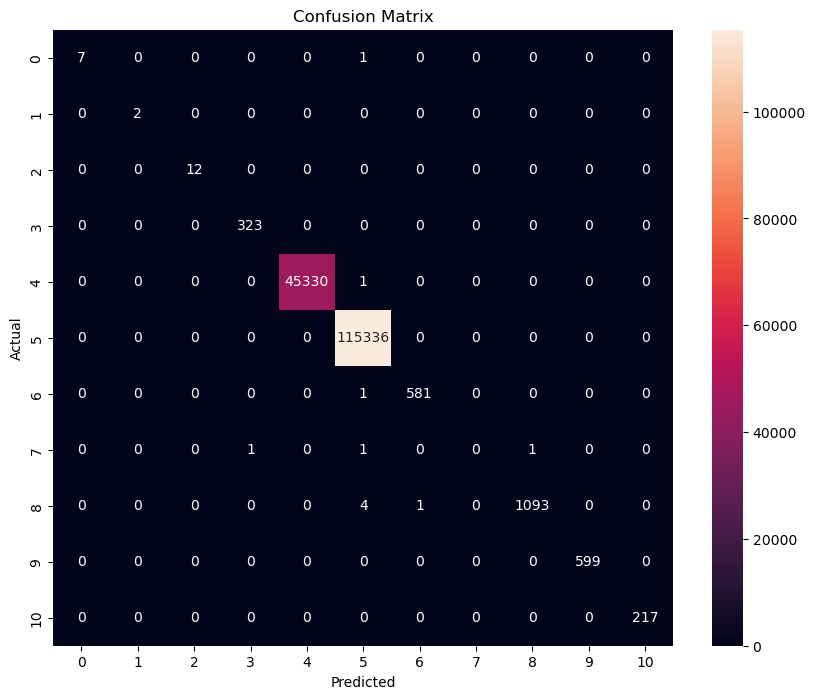

In [51]:
#Confusion Matrix

cm= confusion_matrix(y_test,y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [47]:
# Will preform XGboost

xgb= XGBClassifier(n_estimators=100,max_depth=6,learning_rate=0.1,random_state=42,eval_metric='mlogloss')

xgb.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [48]:
#Predict the model

y_pred_xgb= xgb.predict(X_test)

In [123]:
report= print(classification_report(y_test,y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      0.88      0.93         8
           1       1.00      0.50      0.67         2
           2       1.00      1.00      1.00        12
           3       1.00      1.00      1.00       323
           4       1.00      1.00      1.00     45331
           5       1.00      1.00      1.00    115336
           6       1.00      1.00      1.00       582
           7       1.00      0.33      0.50         3
           8       1.00      1.00      1.00      1098
           9       1.00      1.00      1.00       599
          10       1.00      1.00      1.00       217

    accuracy                           1.00    163511
   macro avg       1.00      0.88      0.92    163511
weighted avg       1.00      1.00      1.00    163511



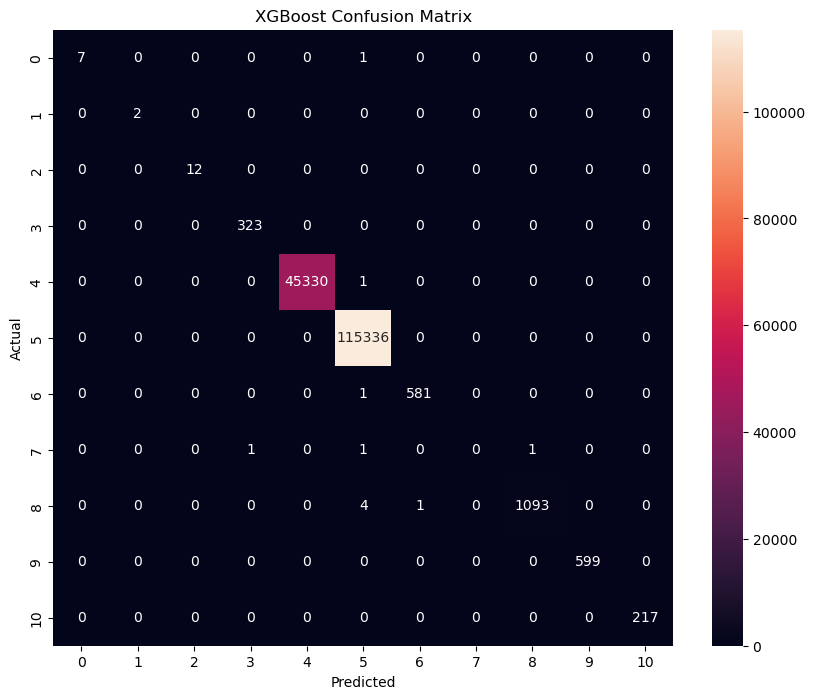

In [50]:

cm= confusion_matrix(y_test,y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.show()

In [68]:
# Will check the preformarnce of Decision Tress as well

dt= DecisionTreeClassifier(class_weight='balanced', random_state=42)

dt.fit(X_train,y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=42)

In [70]:
y_pred_dt= dt.predict(X_test)

In [71]:
print(classification_report(y_test,y_pred_dt))

              precision    recall  f1-score   support

           0       0.86      0.75      0.80         8
           1       1.00      0.50      0.67         2
           2       1.00      1.00      1.00        12
           3       1.00      1.00      1.00       323
           4       1.00      1.00      1.00     45331
           5       1.00      1.00      1.00    115336
           6       1.00      1.00      1.00       582
           7       1.00      0.33      0.50         3
           8       1.00      1.00      1.00      1098
           9       1.00      1.00      1.00       599
          10       1.00      1.00      1.00       217

    accuracy                           1.00    163511
   macro avg       0.99      0.87      0.90    163511
weighted avg       1.00      1.00      1.00    163511



In [72]:
# Random Forest- Macro F1-score is 0.90
# XGBoost- Macro F1-score is 0.92
# Decision Tree- Macro F1-score is 0.90    



# XGBoost model preform well compare to other model Macro F1 score as 0.92. hence,XGBoost result is Final result.

In [78]:
print(le_dict['attack'].classes_)

['0' '1' '10' '2' '3' '4' '5' '6' '7' '8' '9']


In [110]:
#Unable to map the lable as I have encoded categorical variable twice. Hence, re-run the data file to till encoding path. 

print(le_dict['attack'].classes_)

['BufferOverflow' 'FTPWrite' 'GuessPassword' 'NMap' 'Neptune' 'Normal'
 'PortSweep' 'RootKit' 'Satan' 'Smurf' 'back']


In [111]:
print(data['attack'].value_counts().sort_index())

attack
0         30
1          8
2         53
3       1554
4     227228
5     576710
6       2964
7         10
8       5019
9       3007
10       968
Name: count, dtype: int64


In [120]:
#Renaming back to "Back"

data['attack'] = data['attack'].replace({'back':'Back'})

In [119]:
data['attack_name'] = le_dict['attack'].inverse_transform(data['attack'])

print(data[['attack', 'attack_name']].head())

   attack attack_name
0       5      Normal
1       5      Normal
2       5      Normal
3       5      Normal
4       5      Normal


In [129]:
report = classification_report(
    y_test,
    y_pred_xgb,
    target_names=le_dict['attack'].classes_,
    output_dict=True)

report_df = pd.DataFrame(report).transpose()


In [130]:
report_df.to_csv("C:\Projects\oct_python\src\python/Multinomial_XGBoost_Report.csv")

In [131]:
print("Report saved successfully")

Report saved successfully


In [132]:
## For Binomial classification, you can create attack variable with attack vs. normal 

In [313]:
data_bin= data.copy()

In [314]:
data_bin.shape

(817551, 42)

In [316]:
#checking attack values

data_bin['attack'].value_counts().sort_index()

attack
BufferOverflow        30
FTPWrite               8
GuessPassword         53
NMap                1554
Neptune           227228
Normal            576710
PortSweep           2964
RootKit               10
Satan               5019
Smurf               3007
back                 968
Name: count, dtype: int64

In [331]:
#Create binary target

data_bin['attack_binary']= data_bin['attack'].apply(lambda x:'Normal' if x=='Normal' else 'Attack')

In [335]:
data_bin.head(2)

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,attack_binary
0,0.0,0,0,0,0.00215,0.45076,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Normal,Normal
1,0.0,0,0,0,0.00162,0.04528,0,0.0,0.0,0.0,...,0.1,0.0,0.1,0.0,0.0,0.0,0.0,0.0,Normal,Normal


In [333]:
data_bin['attack_binary'].value_counts()

attack_binary
Normal    576710
Attack    240841
Name: count, dtype: int64

In [336]:
data_bin.shape

(817551, 43)

In [337]:
data_bin['attack_binary'].value_counts(normalize=True)*100

attack_binary
Normal    70.541165
Attack    29.458835
Name: proportion, dtype: float64

In [351]:
#Encoding 

le_bin= LabelEncoder()

data_bin['attack_binary']= le_bin.fit_transform(
    data_bin['attack_binary'].astype(str)
)

In [352]:
print(le_bin.classes_)

['0' '1']


In [356]:
print(data_bin['attack_binary'].dtype)

int32


In [362]:
print(X.dtypes[X.dtypes=='object'])

protocol_type    object
service          object
flag             object
dtype: object


In [373]:
#X column still contains text.Need to encode them before train a model

for col in ['protocol_type','service','flag']:
    le= LabelEncoder()
    data_bin[col]= le.fit_transform(data_bin[col].astype(str))

In [374]:
print(data_bin.select_dtypes(include='object').columns)

Index(['attack'], dtype='object')


In [389]:
#Creating X and y

X = data_bin.drop(['attack', 'attack_binary'], axis=1)
y = data_bin['attack_binary']

print(type(X))
print(type(y))

print(X.shape)
print(y.shape)

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>
(817551, 41)
(817551,)


In [390]:
print(X.select_dtypes(include='object').columns)

Index([], dtype='object')


In [396]:
#Spliting into train and test

X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [397]:
print(type(y_train))
print(y_train.head())
print(y_train.nunique())

<class 'pandas.core.series.Series'>
86571     1
394870    1
14114     1
35428     1
516908    1
Name: attack_binary, dtype: int32
2


In [398]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(654040, 41)
(163511, 41)
(654040,)
(163511,)


In [399]:
#Will train XGBoost as XGBosst preformed best score in Multinomial classification

xgb_bin= XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metrics='logloss',
    n_jobs=-1
)

xgb_bin.fit(X_train,y_train)
    

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None,
              eval_metrics='logloss', feature_types=None, feature_weights=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1, ...)

In [402]:
#Prediction

y_pred_xgb= xgb_bin.predict(X_test)

In [403]:
#Check accuracy

print(classification_report(y_test,y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     48168
           1       1.00      1.00      1.00    115343

    accuracy                           1.00    163511
   macro avg       1.00      1.00      1.00    163511
weighted avg       1.00      1.00      1.00    163511



In [407]:
#saving the report

report = classification_report(
    y_test,
    y_pred_xgb,
    target_names=['Attack','Normal'],
    output_dict=True)

report_bin = pd.DataFrame(report).transpose()

In [409]:
report_bin.to_csv("C:\Projects\oct_python\src\python/Binomial_classification_xgb.csv")